###  This notebook calculates 0-D RE evolution during a Disruption

 Loading Modules

In [1]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [2]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp
importlib.reload(RE)

<module 'RE' from 'c:\\Users\\grace\\OneDrive - Wellesley College\\Desktop\\RE_Solver\\RE.py'>

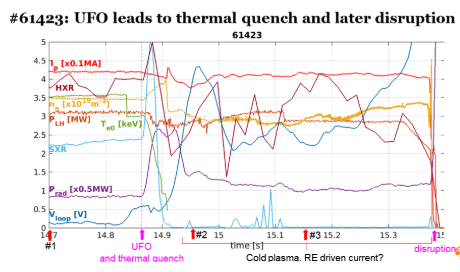

## Instantiate solver and define settings

In [3]:
solver = RE.solver0D()
solver.display() # Show default values


 Constants:
Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0
tmax [s] = 0.005
Zeff_scale [-] =1.0
device [-] = SPARC


In [4]:
# Change solver settings

# Constants 
solver.R0 = 2.535 # Major Radius, [m]
solver.a = 0.5240  # Minor Radius, [m]
solver.ni = 2.5e19 # 2.50e19 (volume average), 4.09e+19 (core value) # ion density in plasma fuel, per m**3
solver.L = 2.04e-06        # plasma internal inductance [H] calculated as L = 2*W / Ip², 
solver.k = 1.328       # elongation
solver.n_imp = 1e-10
solver.Btor = 5 # Tesla

# Initial Conditions
solver.I0 = 0.421e6        # [A], Initial Plasma Current
solver.T0 = 3.55e03   # [eV], initial temperature
solver.Tf = 300       # [eV], post-TQ final temperature
solver.t0 = 50e-3     # [s] TQ duration
solver.Ir0 = 0.15e6   # [A], #  Initial RE current estimated to be equal to the LH-driven current fraction before TQ in the assumption that all LH-generated fast electrons become RE. This estimate must be considered as an upper limit.

# RE Sources
solver.iCompton = 0 # Turn on activated sources
solver.iTritium = 0
solver.iAvalanche = 1
solver.iDreicer = 1

solver.display()


 Constants:
Major radius R0 [m] = 2.535
Minor radius a [m] = 0.524
Elongation k [-] = 1.328
ni [per cubic m] = 2.5e+19
Inductance L [Henry] = 2.04e-06
Btor [Tesla] = 5

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.21e+05
Init. RE Current Ir0 [A] = 1.5e+05
Init. Temp. T0 [eV] = 3.55e+03
Final Temp. Tf [eV] = 300
Temp. decay time t0 [s] = 0.05
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-10
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1

 Other Settings: 

tstart [s] = 0
tmax [s] = 0.005
Zeff_scale [-] =1.0
device [-] = SPARC


# With non-zero driving Loop Voltage

In [5]:

# Loop Voltage
solver.V0 = 0.1
solver.Vf = 4.5

# Temperature
solver.T0 = 3.0e3
solver.Tf = 350
solver.t0 = 18e-3
solver.tstart = 50e-3


# Impurity
solver.Z_imp = 74 # impurity atomic no.
solver.A_imp = 184 # impurity weight
solver.n_imp = 0.5e-3 * solver.ni
solver.prescibe_nz_evolution = True
solver.Zeff_scale = 0.85

# RE
solver.Ir0 = 0.15e6 * 0.25

solver.display()


 Constants:
Major radius R0 [m] = 2.535
Minor radius a [m] = 0.524
Elongation k [-] = 1.328
ni [per cubic m] = 2.5e+19
Inductance L [Henry] = 2.04e-06
Btor [Tesla] = 5

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 4.21e+05
Init. RE Current Ir0 [A] = 3.75e+04
Init. Temp. T0 [eV] = 3e+03
Final Temp. Tf [eV] = 350
Temp. decay time t0 [s] = 0.018
Init. Vloop V0 [V] = 0.1
Final Vloop Vf [V] = 4.5

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1.25e+16
Added Impurity Z, A [-] = 74, 184

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1

 Other Settings: 

tstart [s] = 0.05
tmax [s] = 0.005
Zeff_scale [-] =0.85
device [-] = SPARC


In [6]:
# solve
solver.tmax = 550e-3 # end time [s]
solver.idiag = True # calculate detailed output
t, Ip, Ir, Wk = solver.solve()

# Results

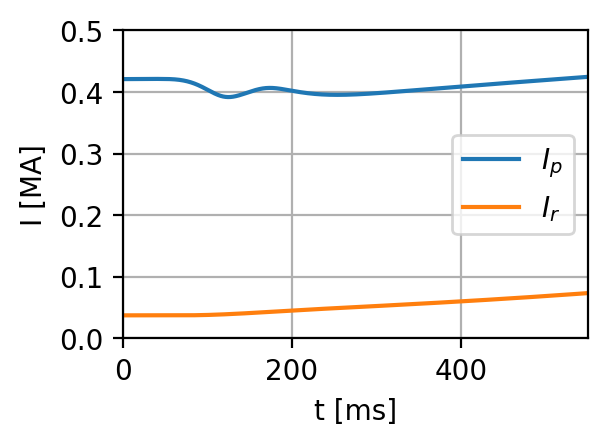

In [7]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t*1e3,Ip/1e6,label='$I_p$')
plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim([0,0.5])
plt.xlim([0,solver.tmax*1e3])

plt.legend()


<>:35: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:56: SyntaxWarning: invalid escape sequence '\g'
<>:35: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:56: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_54840\2626099935.py:35: SyntaxWarning: invalid escape sequence '\p'
  axs[1, 2].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_54840\2626099935.py:37: SyntaxWarning: invalid escape sequence '\p'
  axs[1, 2].plot(d['t'] * 1e3, d['EoED'] * 1e4, label='$E_\parallel/E_D \\times 10^4$')
C:\Users\grace\AppData\Local\Temp\ipykernel_54840\2626099935.py:56: SyntaxWarning: invalid escape sequence '\g'
  axs[2, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')


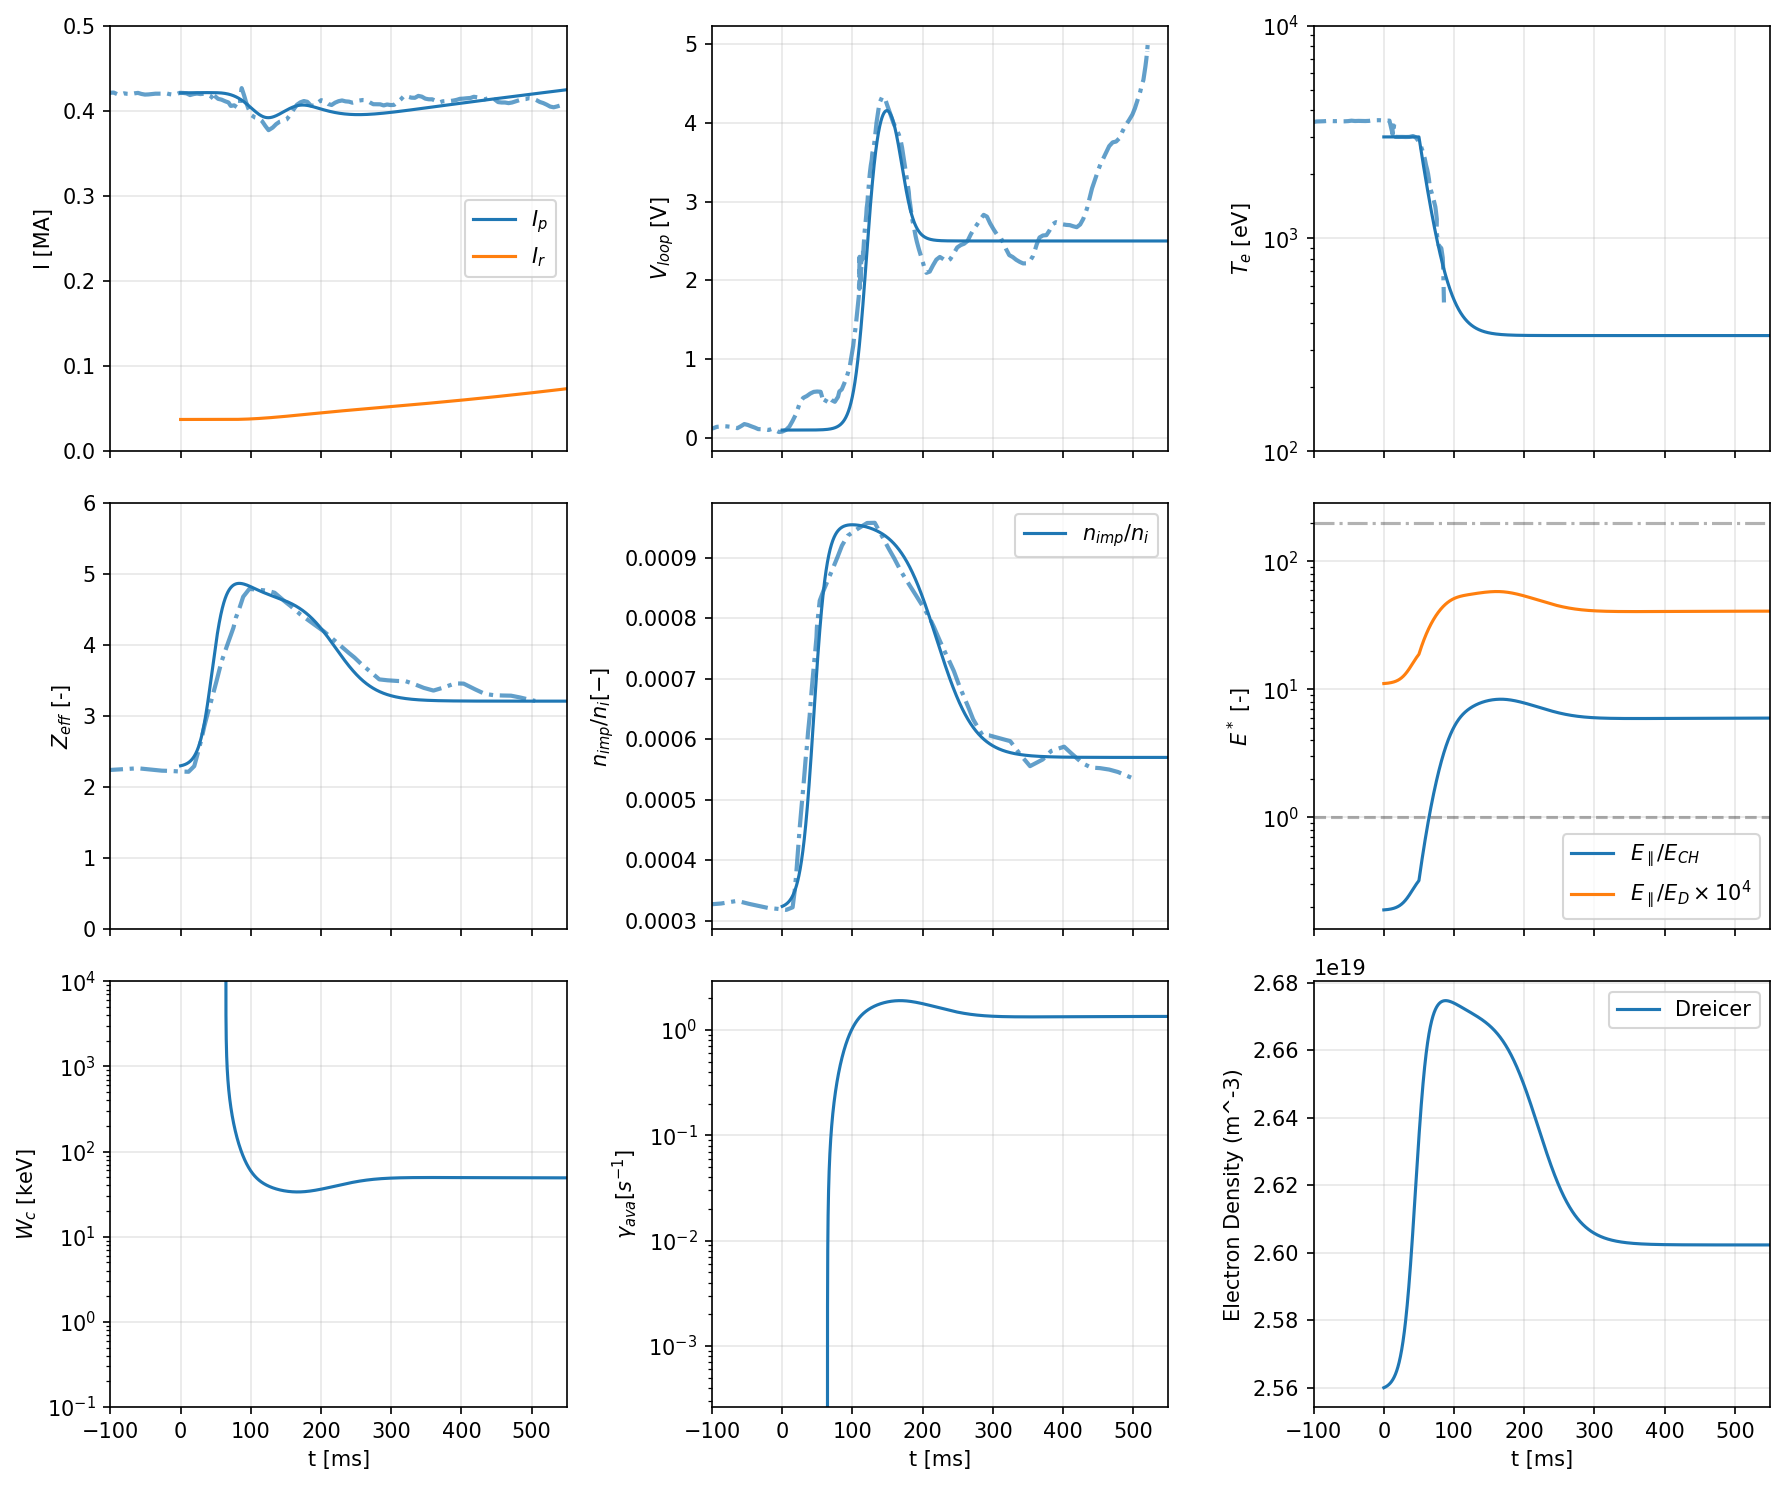

In [9]:
d = solver.diag

fig, axs = plt.subplots(3, 3, sharex=True, figsize=(12, 10), dpi=150)

# ==========================================
# ROW 0: Currents, Loop Voltage, & Te
# ==========================================
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()
axs[0, 0].set_ylim([0, 0.5])

axs[0, 1].plot(d['t'] * 1e3, d['Vloop'])
axs[0, 1].set_ylabel('$V_{loop}$ [V]')

axs[0, 2].plot(d['t'] * 1e3, d['Te'])
axs[0, 2].set_ylabel('$T_e$ [eV]')
axs[0, 2].set_ylim([100, 1e4])
axs[0, 2].set_yscale('log')

# ==========================================
# ROW 1: Zeff, Impurities, & Energy Scales
# ==========================================
axs[1, 0].plot(d['t'] * 1e3, d['Zeff'])
axs[1, 0].set_ylabel('$Z_{eff}$ [-]')
axs[1, 0].set_ylim([0, 6])

# MOVED: nimp/ni now placed directly after Zeff
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# SHIFTED: E* fields moved to row 1, col 2
axs[1, 2].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[1, 2].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[1, 2].plot(d['t'] * 1e3, d['EoED'] * 1e4, label='$E_\parallel/E_D \\times 10^4$')
axs[1, 2].axhline(2e-2 * 1e4, color='k', linestyle='-.', alpha=0.3)
axs[1, 2].set_ylabel('$E^*$ [-]')
axs[1, 2].set_yscale('log')
axs[1, 2].legend()

# ==========================================
# ROW 2: Critical Energy & RE Kinetics
# ==========================================
# SHIFTED: Wc moved down to row 2, col 0
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[2, 0].plot(d['t'] * 1e3, Wc / 1e3)
axs[2, 0].set_ylabel('$W_c$ [keV]')
axs[2, 0].set_yscale('log')
axs[2, 0].set_ylim([1e-1, 1e4])

axs[2, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[2, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[2, 1].set_yscale('log')

#axs[2, 2].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 2].plot(d['t'] * 1e3, d['ne'], label='Dreicer')
#axs[2, 2].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')

axs[2, 2].set_ylabel('Electron Density (m^-3)')
#axs[2, 2].set_yscale('log')
#axs[2, 2].set_ylim([1e6, 1e20])
axs[2, 2].legend()

# ==========================================
# Global Formatting
# ==========================================
for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([-100, d['t'].max() * 1e3])

# Apply X-axis labels to the bottom row (Row 2)
for ax in axs[2, :]:
    ax.set_xlabel('t [ms]')

# --- Experimental Overlays ---
tshift = 120e-3

ip = np.loadtxt('./data/WEST_data/WEST_Ip_x0p1MA.csv', delimiter=',')
axs[0, 0].plot((ip[:, 0] - ip[0, 0] - tshift) * 1e3, ip[:, 1] * 0.1, '-.', color='tab:blue', alpha=0.7,linewidth=2)

vext = np.loadtxt('./data/WEST_data/WEST_Vloop_V.csv', delimiter=',')
axs[0, 1].plot((vext[:, 0] - vext[0, 0] - tshift) * 1e3, vext[:, 1], '-.', color='tab:blue', alpha=0.7,linewidth=2)

te = np.loadtxt('./data/WEST_data/WEST_Te_keV.csv', delimiter=',')
axs[0, 2].plot((te[:, 0] - te[0, 0] - tshift) * 1e3, te[:, 1] * 1e3, '-.', color='tab:blue', alpha=0.7,linewidth=2)

zeff = np.loadtxt('./data/WEST_data/WEST_Zeff.csv', delimiter=',')
axs[1, 0].plot((zeff[:, 0] - zeff[0, 0] - tshift) * 1e3, zeff[:, 1], '-.', color='tab:blue', alpha=0.7,linewidth=2)

cW = np.loadtxt('./data/WEST_data/WEST_cW_x1e-4.csv', delimiter=',')
axs[1, 1].plot((cW[:, 0] - cW[0, 0] - tshift) * 1e3, cW[:, 1] * 1e-4, '-.', color='tab:blue', alpha=0.7,linewidth=2)


fig.set_facecolor('w')
plt.tight_layout()
plt.show()